# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Hernando, Claire Marie M. 
- _Student No._: 2024-12904
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

#### **Figure 1. Synthetic data interpolation.** 
![Synthetic data interpolation](synthetic_data_interpolation.jpg) <img src="../Claire/Exercise 9/synthetic_data_interpolation.jpg" width=45%>
***Figure 1** shows the plot comparing the sampled sine data with the linear, nearest, quadratic, and cubic interpolations.*

#### **Figure 2. Real-world data reconstruction.** 
![Interpolation of Real-world Data](interp_real_world_data.jpg) <img src="../Claire/Exercise 9/interp_real_world_data.jpg" width=45%>
***Figure 2.e** shows the plot of the reconstruction of the Dow Jones time-series dataset in different sampling fractions.*

![Different Interpolation Methods on Sampled Real-world Data](interp_sampled_real_world_data.jpg) <img src="../Claire/Exercise 9/interp_sampled_real_world_data.jpg" width=45%>
***Figure 3** shows the plot of the reconstruction of the sampled Dow Jones time-series dataset using different interpolation methods.*


### Report discussion

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

### Other comments
- EDIT ME
- A self-reflection can be placed here. This portion is not graded.

---
## Section 2: Code

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

In [ ]:
def f(x):
    return np.sin(x)

x_data = np.linspace(0, 2 * np.pi, 1000)
y_data = f(x_data)

n_samples = 15
x_samples = np.linspace(0, 2 * np.pi, n_samples)
y_samples = f(x_samples)

interp_linear = interpolate.interp1d(x_samples, y_samples, kind='linear')
interp_cubic = interpolate.interp1d(x_samples, y_samples, kind='cubic')
interp_nearest = interpolate.interp1d(x_samples, y_samples, kind='nearest')
interp_quadratic = interpolate.interp1d(x_samples, y_samples, kind='quadratic')

y_lin = interp_linear(x_data)
y_cubic = interp_cubic(x_data)
y_nearest = interp_nearest(x_data)
y_quadratic = interp_quadratic(x_data)

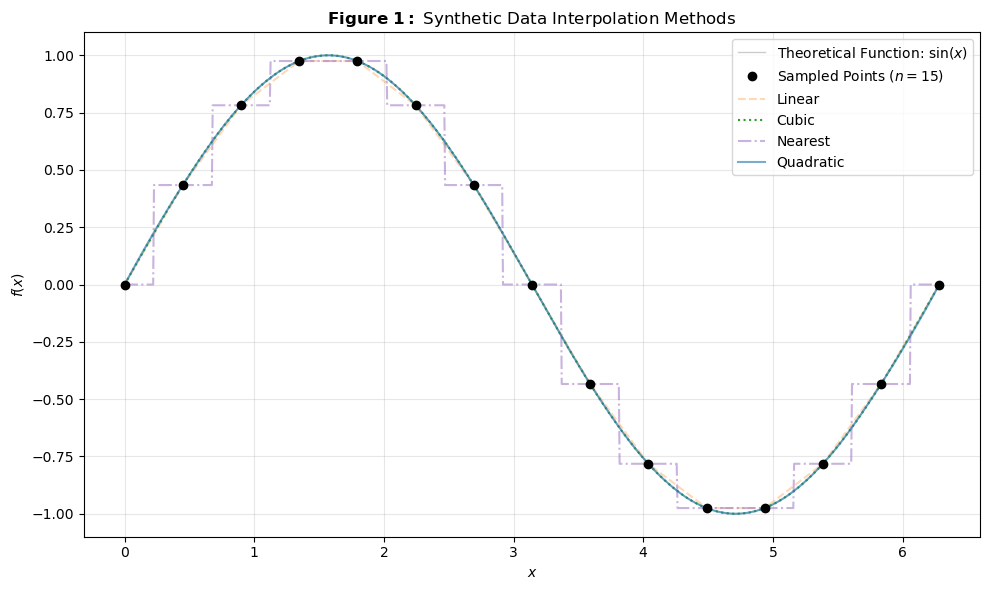

In [27]:
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(x_data, y_data, 'k-', label='Theoretical Function: $\sin(x)$', alpha=0.2, lw=1)
ax.plot(x_samples, y_samples, 'ko', label=f'Sampled Points ($n = {n_samples}$)', zorder=5)
ax.plot(x_data, y_lin, '--', label='Linear', color='tab:orange', alpha=0.3)
ax.plot(x_data, y_cubic, ':', label='Cubic', color='tab:green', alpha=1.0)
ax.plot(x_data, y_nearest, '-.', label='Nearest', color='tab:purple', alpha=0.5)
ax.plot(x_data, y_quadratic, '-', label='Quadratic', color='tab:blue', alpha=0.6)

ax.set_title(r'$\bf{Figure\ 1:}$ Synthetic Data Interpolation Methods')
ax.set_xlabel('$x$')
ax.set_ylabel('$f(x)$')
ax.legend(loc='best')

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('synthetic_data_interpolation.jpg', dpi=150)
plt.show()

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [ ]:
# !wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [10]:
filepath = "rawdatafile.txt"

In [11]:
# Loading the data 
RealRawData = np.loadtxt(filepath)
x_fulldata= np.arange(len(RealRawData)) # To arrange in chronological order
y_fulldata = RealRawData

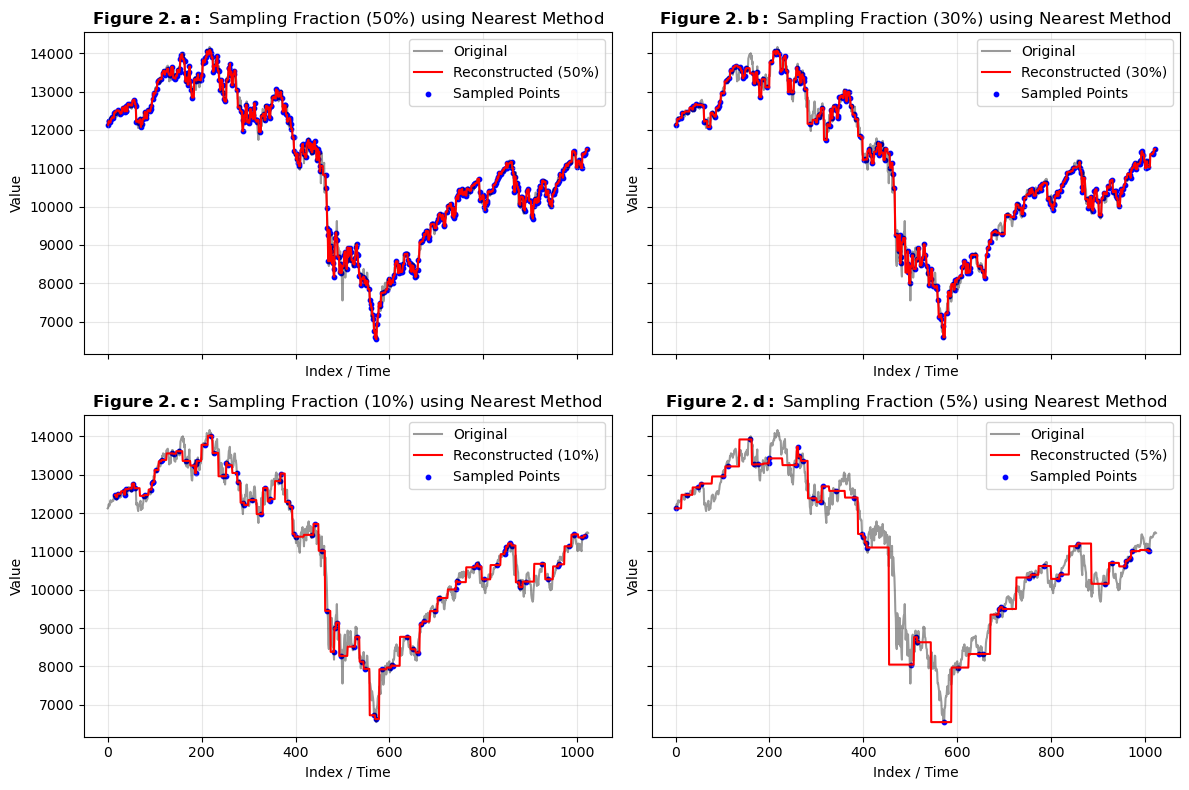

In [24]:
sampling_fractions = [0.50, 0.30, 0.10, 0.05]
label = ['a', 'b', 'c', 'd']
kind = 'nearest' # Change according to method preference 

# Plotting
fig, axes = plt.subplots(2, 2, figsize=(12,8), sharex=True, sharey=True)

for frac, ax, lbl in zip(sampling_fractions, axes.flatten(), label):
    num_samples = int(len(RealRawData) * frac) # Randomly select fraction of indices 
    sample_indices = np.sort(np.random.choice(len(RealRawData), size=num_samples, replace=False)) # Ensuring endpoints are included for clean boundary interpolation

    x_sampled = x_fulldata[sample_indices]
    y_sampled = y_fulldata[sample_indices]

    # Reconstructing using interpolation functions
    interp_method = interpolate.interp1d(x_sampled, y_sampled, kind=kind)

    # Evaluating over original series
    x_interp = np.linspace(x_sampled.min(), x_sampled.max(), len(RealRawData))
    y_interp = interp_method(x_interp)

    # Plotting the comparison 
    ax.plot(x_fulldata, y_fulldata, label='Original', color='black', alpha=0.4)
    ax.plot(x_interp, y_interp, label=f'Reconstructed ({int(frac*100)}%)', color='red')
    ax.scatter(x_sampled, y_sampled, color='blue', s=10, label='Sampled Points')
    ax.set_title(fr'$\bf{{Figure\ 2.{lbl}:}}$ Sampling Fraction ({int(frac*100)}%) using {kind.capitalize()} Method') 
    ax.set_xlabel('Index / Time')
    ax.set_ylabel('Value')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

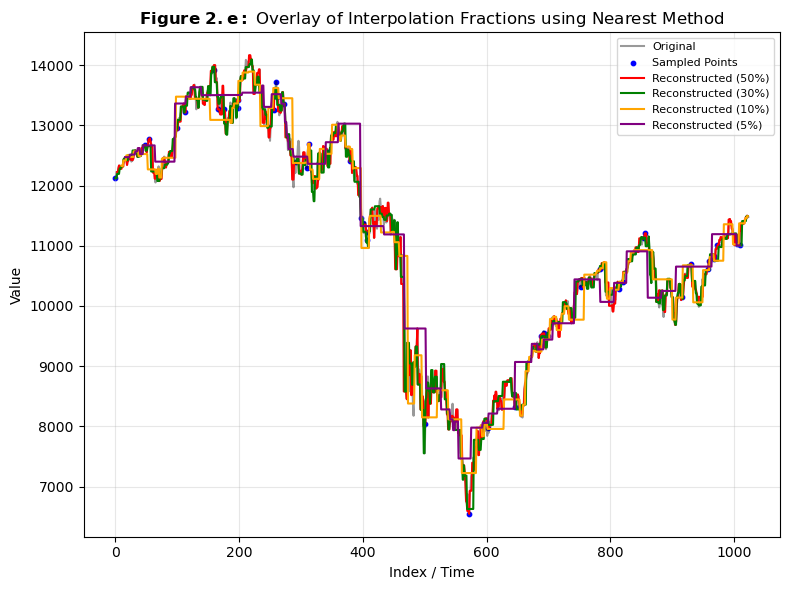

In [28]:
# Overlaying the reconstructed curves in a single, unified plot
sampling_fractions = [0.50, 0.30, 0.10, 0.05]
colors = ['red', 'green', 'orange', 'purple']
kind = 'nearest' # Change according to method preference 

# Plotting
fig, ax = plt.subplots(figsize=(8,6))

# Plotting original dataset
ax.plot(x_fulldata, y_fulldata, label='Original', color='black', alpha=0.4)
ax.scatter(x_sampled, y_sampled, color='blue', s=10, label='Sampled Points')

for frac, color in zip(sampling_fractions, colors):
    num_samples = int(len(RealRawData) * frac) # Randomly select fraction of indices 
    sample_indices = np.sort(np.random.choice(len(RealRawData), size=num_samples, replace=False)) # Ensuring endpoints are included for clean boundary interpolation

    x_sampled = x_fulldata[sample_indices]
    y_sampled = y_fulldata[sample_indices]

    # Reconstructing using interpolation functions
    interp_method = interpolate.interp1d(x_sampled, y_sampled, kind=kind)

    # Evaluating over original series
    x_interp = np.linspace(x_sampled.min(), x_sampled.max(), len(RealRawData))
    y_interp = interp_method(x_interp)

    # Plotting the reconstructed fraction on the same axis
    ax.plot(x_interp, y_interp, label=f'Reconstructed ({int(frac*100)}%)', color=color)

ax.set_title(fr'$\bf{{Figure\ 2.e:}}$ Overlay of Interpolation Fractions using {kind.capitalize()} Method')
ax.set_xlabel('Index / Time')
ax.set_ylabel('Value')
ax.legend(loc='best', fontsize=8)
ax.grid(True, alpha=0.3)
    
plt.tight_layout()
plt.savefig('interp_real_world_data.jpg', dpi=150)
plt.show()

In [ ]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

In [ ]:
# code here

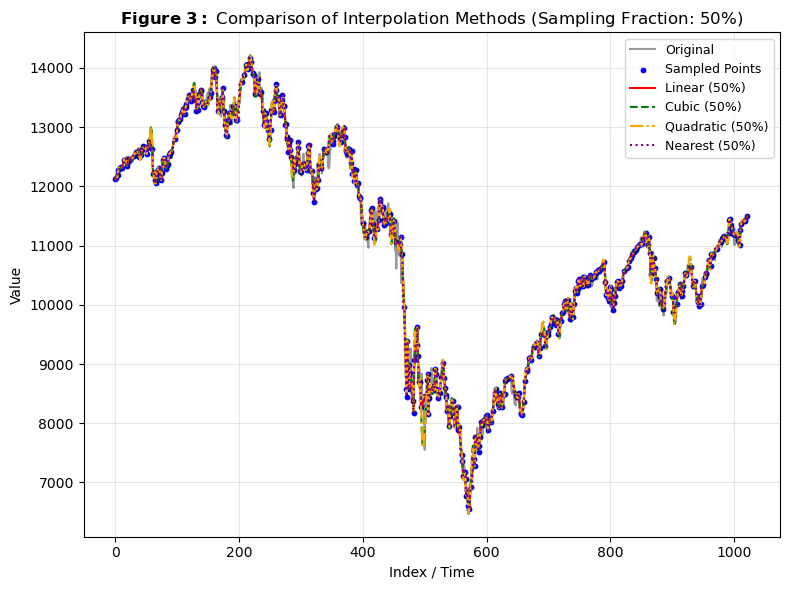

In [32]:
sampling_fraction = 0.50
kinds = ['linear', 'cubic', 'quadratic', 'nearest']
colors = ['red', 'green', 'orange', 'purple']
linestyles = ['-', '--', '-.', ':']

fig, ax = plt.subplots(figsize=(8,6))

# Calculating sampled indices and variables 
num_samples = int(len(RealRawData) * sampling_fraction)
sample_indices = np.sort(np.random.choice(len(RealRawData), size=num_samples, replace=False)) # Ensuring endpoints are included for clean boundary interpolation

x_sampled = x_fulldata[sample_indices]
y_sampled = y_fulldata[sample_indices]

# Plotting original dataset and scatter points
ax.plot(x_fulldata, y_fulldata, label='Original', color='black', alpha=0.4)
ax.scatter(x_sampled, y_sampled, color='blue', s=10, label='Sampled Points')

for k, color, ls in zip(kinds, colors, linestyles):
    # Reconstructing using interpolation methods 
    interp_method = interpolate.interp1d(x_sampled, y_sampled, kind=k)

    # Evaluating over original series
    x_interp = np.linspace(x_sampled.min(), x_sampled.max(), len(RealRawData))
    y_interp = interp_method(x_interp)

    # Plotting the reconstructed fraction on the same axis 
    ax.plot(x_interp, y_interp, label=f'{k.capitalize()} ({int(sampling_fraction*100)}%)', color=color, linestyle=ls, linewidth=1.5)

ax.set_title(fr'$\bf{{Figure\ 3:}}$ Comparison of Interpolation Methods (Sampling Fraction: {int(sampling_fraction*100)}%)')
ax.set_xlabel('Index / Time')
ax.set_ylabel('Value')
ax.legend(loc='best', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('interp_sampled_real_world_data.jpg', dpi=150)
plt.show()

### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---